# Chunking Experiment: how chunk size and overlap change retrieval

Every RAG system has to cut its documents into chunks before embedding them, and the choice is usually a guess
("1,000 characters, 200 overlap"). This notebook measures it instead.

1. **Corpus:** three chapters of the FAA *Pilot's Handbook of Aeronautical Knowledge* (public domain):
   11 Aircraft Performance, 12 Weather Theory, 15 Airspace.
2. **Labelled questions:** 20 questions, each tagged with its chapter and the words a correct passage must contain.
3. **Sweep:** 2 strategies (fixed-size windows, whole sentences) × 4 sizes × 3 overlaps = 24 settings, each scored
   on keyword hit@5, MRR, and how much text the LLM would have to read.
4. **Answers:** with the best setting, a local LLM (Qwen in LM Studio) answers with citations, and must reply
   *"Not in the handbook passages."* for questions the handbook doesn't cover (binary heaps, the World Series).

Needs: LM Studio running with the model in `LLM_MODEL` (see the repo's `.env.example`) for step 4 only.

In [1]:
# Cell 1 — Setup
import json, os, sys
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True))
PROJECT_DIR = Path.cwd().parent if Path.cwd().name in ("notebooks", "src") else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "src"))
import phak, chunking as ck, answer as an

CORPUS_DIR = PROJECT_DIR / "corpus"
RAW_DIR = PROJECT_DIR / "data" / "raw"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
K = 5

In [2]:
# Cell 2 — Corpus: download the three chapter PDFs from faa.gov once, then reuse the saved text
corpus = phak.load_corpus(CORPUS_DIR)
if len(corpus) < len(phak.CHAPTERS):
    corpus = phak.build_corpus(RAW_DIR, CORPUS_DIR)
    print("Built the corpus from faa.gov")
for ch, text in corpus.items():
    print(f"Chapter {ch} ({phak.CHAPTERS[ch][0]}): {len(text):,} characters, {len(text.split()):,} words")
print("\nStart of chapter 11:\n" + corpus[11][:500])

Chapter 11 (Aircraft Performance): 105,254 characters, 17,119 words
Chapter 12 (Weather Theory): 76,741 characters, 12,559 words
Chapter 15 (Airspace): 35,103 characters, 5,568 words

Start of chapter 11:
Introduction This chapter discusses the factors that affect aircraft performance, which include the aircraft weight, atmospheric conditions, runway environment, and the fundamental physical laws governing the forces acting on an aircraft.
Importance of Performance Data The performance or operational information section of the Aircraft Flight Manual/Pilot’s Operating Handbook (AFM/ POH) contains the operating data for the aircraft; that is, the data pertaining to takeoff, climb, range, endurance,


In [3]:
# Cell 3 — Questions, and a check that the answer keywords are fair
# A keyword that never appears in its chapter makes a question impossible; one that appears in most chunks makes it free.
questions = pd.read_csv(PROJECT_DIR / "eval" / "questions.csv")
out_of_scope = pd.read_csv(PROJECT_DIR / "eval" / "out_of_scope.csv")

reference = ck.build_chunks(corpus, "fixed", 600, 0)
def keyword_share(q):
    texts = reference.loc[reference.chapter == q.chapter, "text"].str.lower()
    return texts.map(lambda t: any(k in t for k in ck.keywords_of(q.keywords))).mean()

questions["keyword_in_chapter"] = [any(k in corpus[q.chapter].lower() for k in ck.keywords_of(q.keywords))
                                   for q in questions.itertuples()]
questions["chunks_with_keyword"] = [round(keyword_share(q), 3) for q in questions.itertuples()]
print(f"{len(questions)} in-scope questions, {len(out_of_scope)} out-of-scope questions")
print(f"Impossible (keyword not in its chapter): {(~questions.keyword_in_chapter).sum()}")
print(f"Too easy (keyword in over 30% of the chapter's 600-character chunks): {(questions.chunks_with_keyword > 0.3).sum()}")
display(questions)

20 in-scope questions, 4 out-of-scope questions
Impossible (keyword not in its chapter): 0
Too easy (keyword in over 30% of the chapter's 600-character chunks): 0


,question,chapter,keywords,keyword_in_chapter,chunks_with_keyword
0,What is density altitude?,11,corrected for nonstandard temperature;correcte...,True,0.006
1,What is pressure altitude?,11,standard datum plane,True,0.006
2,How does humidity affect aircraft performance?,11,moist air;water vapor is lighter,True,0.006
3,What is the difference between Vx and Vy?,11,best angle of climb;best angle-of-climb,True,0.006
4,What is an airplane's service ceiling?,11,service ceiling,True,0.011
5,How does runway slope affect takeoff distance?,11,upslope;gradient,True,0.011
6,What types of hydroplaning are there?,11,reverted rubber;viscous hydroplaning;dynamic h...,True,0.017
7,How does a headwind affect takeoff and landing...,11,headwind,True,0.107
8,What is the standard temperature lapse rate?,12,3.5;2 °c per,True,0.008
9,What is a temperature inversion?,12,inversion,True,0.031


In [4]:
# Cell 4 — Embedding model: BGE-small, the same model as project 07 (downloads ~130 MB the first time)
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("BAAI/bge-small-en-v1.5")
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "  # BGE's instruction for queries
embed = ck.EmbeddingCache(lambda texts: model.encode(texts, normalize_embeddings=True, batch_size=64))
def embed_query(texts):
    return model.encode([QUERY_PREFIX + t for t in texts], normalize_embeddings=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [5]:
# Cell 5 — The sweep: 2 strategies × 4 sizes × 3 overlaps, all scored on the same 20 questions
SIZES = [300, 600, 1000, 1600]
OVERLAPS = [0, 0.15, 0.3]
STRATEGIES = ["fixed", "sentence"]

table = ck.sweep(corpus, questions, embed, SIZES, OVERLAPS, STRATEGIES, k=K, embed_query=embed_query)
table.to_csv(OUTPUT_DIR / "chunking_sweep.csv", index=False)
print(f"{len(table)} settings, {len(embed.cache):,} distinct chunks embedded\n")
print(f"keyword hit@{K}:")
display(table.pivot_table(index=["strategy", "size"], columns="overlap", values=f"keyword_hit@{K}"))
print("MRR:")
display(table.pivot_table(index=["strategy", "size"], columns="overlap", values="MRR").round(3))

24 settings, 8,440 distinct chunks embedded

keyword hit@5:


overlap        0.00  0.15  0.30
strategy size                  
fixed    300   0.95  0.85  0.90
         600   0.90  0.95  0.90
         1000  0.90  0.90  0.85
         1600  0.90  0.85  0.85
sentence 300   0.70  0.70  0.75
         600   0.85  0.90  0.80
         1000  0.90  0.80  0.80
         1600  0.80  0.85  0.85

MRR:


overlap         0.00   0.15   0.30
strategy size                     
fixed    300   0.783  0.658  0.729
         600   0.717  0.775  0.688
         1000  0.783  0.710  0.664
         1600  0.718  0.733  0.758
sentence 300   0.539  0.552  0.589
         600   0.689  0.733  0.687
         1000  0.746  0.717  0.654
         1600  0.700  0.679  0.729

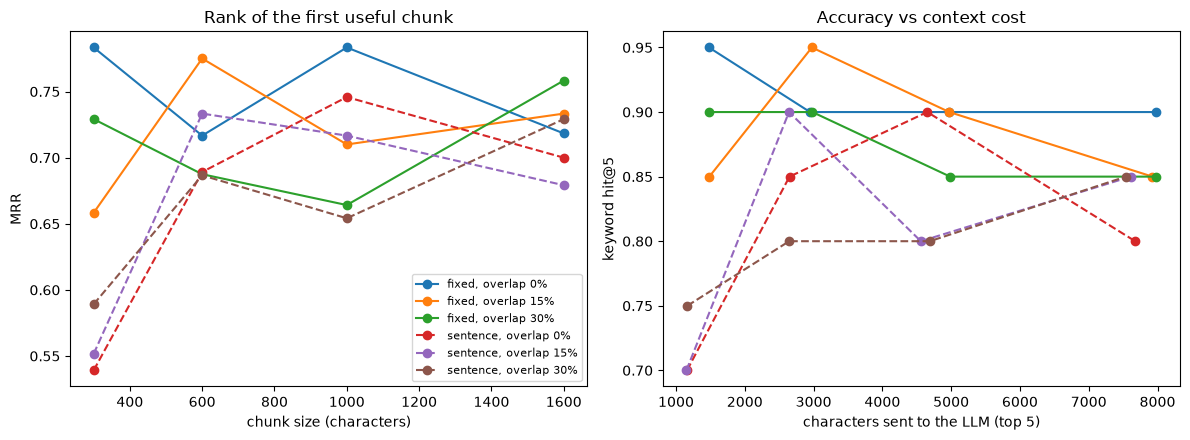

In [6]:
# Cell 6 — Accuracy against cost: what each extra character of context buys
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (strategy, overlap), g in table.groupby(["strategy", "overlap"]):
    style = "-" if strategy == "fixed" else "--"
    label = f"{strategy}, overlap {overlap:.0%}"
    axes[0].plot(g["size"], g["MRR"], style, marker="o", label=label)
    axes[1].plot(g[f"context_chars@{K}"], g[f"keyword_hit@{K}"], style, marker="o", label=label)
axes[0].set(xlabel="chunk size (characters)", ylabel="MRR", title="Rank of the first useful chunk")
axes[1].set(xlabel=f"characters sent to the LLM (top {K})", ylabel=f"keyword hit@{K}", title="Accuracy vs context cost")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "chunking_sweep.png", dpi=150)
plt.show()

In [7]:
# Cell 7 — The best setting, and which questions it still misses
best = ck.best_setting(table, K)
SIZE, OVERLAP = int(best["size"]), int(best["size"] * best["overlap"])
print(f"Best: {best['strategy']} chunks of {SIZE} characters, {OVERLAP} overlap — "
      f"hit@{K} {best[f'keyword_hit@{K}']:.2f}, MRR {best['MRR']:.3f}, {best[f'context_chars@{K}']:,.0f} characters of context")

chunks = ck.build_chunks(corpus, best["strategy"], SIZE, OVERLAP)
vectors = embed(list(chunks.text))
query_vecs = embed_query(list(questions.question))
questions["rank_of_first_hit"] = ck.evaluate(chunks, vectors, questions, query_vecs, K, with_ranks=True)["ranks"]
display(questions[["question", "chapter", "rank_of_first_hit"]])

Best: fixed chunks of 300 characters, 0 overlap — hit@5 0.95, MRR 0.783, 1,479 characters of context


,question,chapter,rank_of_first_hit
0,What is density altitude?,11,3.0
1,What is pressure altitude?,11,1.0
2,How does humidity affect aircraft performance?,11,1.0
3,What is the difference between Vx and Vy?,11,4.0
4,What is an airplane's service ceiling?,11,1.0
5,How does runway slope affect takeoff distance?,11,1.0
6,What types of hydroplaning are there?,11,1.0
7,How does a headwind affect takeoff and landing...,11,1.0
8,What is the standard temperature lapse rate?,12,4.0
9,What is a temperature inversion?,12,1.0


In [8]:
# Cell 8 — Answers from Qwen with citations, and abstention on questions the handbook doesn't cover
chat = an.openai_chat()

def answer_all(chunks, vectors, items, scope):
    out = []
    for q in items.itertuples():
        passages = list(chunks.text.iloc[ck.retrieve(vectors, embed_query([q.question])[0], K)])
        r = {"scope": scope, **an.ask(q.question, passages, chat), "passages": passages}
        if scope == "in":  # end-to-end check: did the answer itself state the labelled fact?
            r["chapter"] = int(q.chapter)
            r["answer_has_keyword"] = r["verdict"] == "answered" and any(
                k in r["answer"].lower() for k in ck.keywords_of(q.keywords))
        out.append(r)
    return out

runs = answer_all(chunks, vectors, questions, "in") + answer_all(chunks, vectors, out_of_scope, "out")
results = pd.DataFrame(runs)
record = {"date": date.today().isoformat(), "model": os.getenv("LLM_MODEL"),
          "setting": {"strategy": best["strategy"], "size": SIZE, "overlap": OVERLAP, "k": K}, "results": runs}
(OUTPUT_DIR / "answers_run.json").write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")

inside, outside = results[results.scope == "in"], results[results.scope == "out"]
print("In-scope verdicts:", inside.verdict.value_counts().to_dict())
print(f"In-scope answers that state the labelled fact: {inside.answer_has_keyword.sum()}/{len(inside)}")
print(f"Out-of-scope questions correctly declined: {outside.abstained.sum()}/{len(outside)}")
pd.set_option("display.max_colwidth", 220)
display(results[["scope", "question", "verdict", "citations", "answer"]])

In-scope verdicts: {'answered': 17, 'abstained': 3}
In-scope answers that state the labelled fact: 17/20
Out-of-scope questions correctly declined: 4/4


,scope,question,verdict,citations,answer
0,in,What is density altitude?,answered,"[1, 3]",Density altitude is the vertical distance above sea level in the standard atmosphere at which a given density is to be found [P1]. It is also defined as the altitude in the standard atmosphere corresponding to a part...
1,in,What is pressure altitude?,answered,"[1, 2]","Pressure altitude is the height above the standard datum plane (SDP) [P1]. It is important as a basis for determining aircraft performance and for assigning flight levels to aircraft operating above 18,000 feet [P2]."
2,in,How does humidity affect aircraft performance?,answered,"[1, 2, 5]","Humidity is an important factor in aircraft performance because water vapor is lighter than air, making moist air lighter than dry air [P1]. While humidity alone is usually not considered essential for calculating de..."
3,in,What is the difference between Vx and Vy?,answered,"[1, 3, 4]","Based on the provided passages, the difference between Vx and Vy is:\n- Vx is the best angle of climb speed, defined as the speed at which the aircraft obtains the highest altitude in a given horizontal distance [P1]..."
4,in,What is an airplane's service ceiling?,abstained,[],Not in the handbook passages.
5,in,How does runway slope affect takeoff distance?,answered,"[2, 4]","Runway slope affects takeoff distance based on the direction of the gradient. A downsloping runway aids in acceleration on takeoff, resulting in shorter takeoff distances [P2]. Conversely, an upsloping runway impedes..."
6,in,What types of hydroplaning are there?,abstained,[],Not in the handbook passages.
7,in,How does a headwind affect takeoff and landing distance?,answered,"[1, 2, 3]","A headwind allows the aircraft to reach lift-off speed at a lower groundspeed [P1]. Specifically, a headwind that is 10 percent of the takeoff airspeed reduces the takeoff distance approximately 19 percent [P2]. For ..."
8,in,What is the standard temperature lapse rate?,answered,[1],"The standard temperature lapse rate is one in which the temperature decreases at a rate of approximately 3.5 °F or 2 °C per thousand feet up to 36,000 feet [P1]."
9,in,What is a temperature inversion?,answered,"[1, 2, 4]","A temperature inversion is an atmospheric anomaly that changes the typical pattern of decreasing temperature with altitude, occurring when the temperature of the air rises with altitude [P4]. These inversion layers a..."


In [9]:
# Cell 9 — Does the retrieval winner give the best answers?
# hit@5 only asks whether a keyword is somewhere in the top 5. A short chunk can hold the keyword but cut off the
# sentence that answers the question, so re-answer the in-scope questions with the best setting at least twice as large.
larger = table[table["size"] >= 2 * SIZE]
if larger.empty:
    larger = table[table["size"] > SIZE]
alt = ck.best_setting(larger if not larger.empty else table, K)
ALT_SIZE, ALT_OVERLAP = int(alt["size"]), int(alt["size"] * alt["overlap"])
alt_chunks = ck.build_chunks(corpus, alt["strategy"], ALT_SIZE, ALT_OVERLAP)
alt_vectors = embed(list(alt_chunks.text))
alt_inside = pd.DataFrame(answer_all(alt_chunks, alt_vectors, questions, "in"))

def summary(df, setting_row):
    return {"answered": int(df.verdict.eq("answered").sum()), "states the labelled fact": int(df.answer_has_keyword.sum()),
            "abstained": int(df.abstained.sum()), f"retrieval hit@{K}": setting_row[f"keyword_hit@{K}"],
            f"context chars@{K}": round(setting_row[f"context_chars@{K}"])}
comparison = pd.DataFrame({f"{best['strategy']} {SIZE} / {OVERLAP} overlap": summary(inside, best),
                           f"{alt['strategy']} {ALT_SIZE} / {ALT_OVERLAP} overlap": summary(alt_inside, alt)})
display(comparison)
diff = pd.DataFrame({"question": questions.question, "small chunks": inside.verdict.values,
                     "larger chunks": alt_inside.verdict.values})
display(diff[diff["small chunks"] != diff["larger chunks"]])

record["comparison"] = {"setting": {"strategy": alt["strategy"], "size": ALT_SIZE, "overlap": ALT_OVERLAP, "k": K},
                        "results": alt_inside.to_dict(orient="records")}
(OUTPUT_DIR / "answers_run.json").write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")

,fixed 300 / 0 overlap,fixed 600 / 90 overlap
answered,17.00,18.00
states the labelled fact,17.00,16.00
abstained,3.00,2.00
retrieval hit@5,0.95,0.95
context chars@5,1479.00,2975.00


,question,small chunks,larger chunks
4,What is an airplane's service ceiling?,abstained,answered
10,What causes wind to blow from high to low pressure?,abstained,answered
17,"What is the speed limit below 10,000 feet MSL?",answered,abstained


129245